<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/MachineLearningT1_Bai2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Accuracy: 0.725
Confusion Matrix:
[[16  5]
 [ 6 13]]

5 mau du doan dau tien:
BMI: 18.93 Xac suat: 0.031 Nhan: 0
BMI: 29.47 Xac suat: 0.628 Nhan: 1
BMI: 29.02 Xac suat: 0.588 Nhan: 1
BMI: 26.95 Xac suat: 0.394 Nhan: 0
BMI: 37.53 Xac suat: 0.973 Nhan: 1


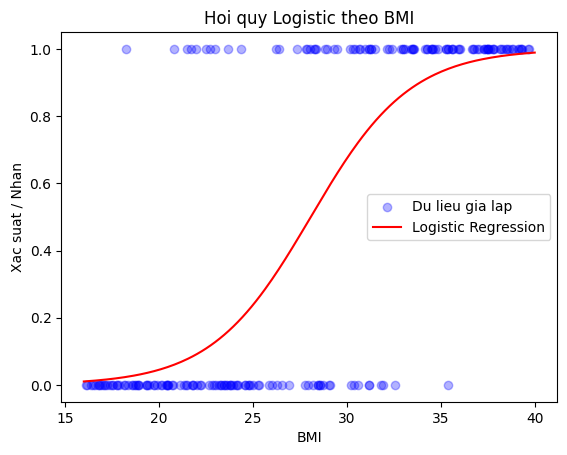

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Tao du lieu gia lap BMI va nhan benh
np.random.seed(42)
BMI = np.random.uniform(16, 40, 200)
xac_suat = 1 / (1 + np.exp(-(BMI - 28) / 3))
mac_benh = np.random.binomial(1, xac_suat)

X = BMI.reshape(-1, 1)
y = mac_benh

# 2. Chia du lieu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

# 3. Huan luyen Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Du doan nhan va xac suat
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 5. Danh gia
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\n5 mau du doan dau tien:")
for i in range(5):
    print("BMI:", round(X_test[i, 0], 2),
          "Xac suat:", round(y_prob[i], 3),
          "Nhan:", y_pred[i])

# 6. Truc quan hoa
x_line = np.linspace(16, 40, 200).reshape(-1, 1)
p_line = model.predict_proba(x_line)[:, 1]

plt.scatter(X, y, color="blue", alpha=0.3,
            label="Du lieu gia lap")
plt.plot(x_line, p_line, color="red",
         label="Logistic Regression")
plt.xlabel("BMI")
plt.ylabel("Xac suat / Nhan")
plt.title("Hoi quy Logistic theo BMI")
plt.legend()
plt.show()


In [2]:

for nguong in [0.5, 0.6, 0.7]:
    du_doan = (y_prob >= nguong).astype(int)
    print("Nguong:", nguong)
    print("Accuracy:", accuracy_score(y_test, du_doan))
    print(confusion_matrix(y_test, du_doan))
    print("------------------------")


Nguong: 0.5
Accuracy: 0.725
[[16  5]
 [ 6 13]]
------------------------
Nguong: 0.6
Accuracy: 0.75
[[18  3]
 [ 7 12]]
------------------------
Nguong: 0.7
Accuracy: 0.725
[[18  3]
 [ 8 11]]
------------------------
